In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from transformers import set_seed

SEED = 42
set_seed(SEED)

# Load Financial PhraseBank Corpus  
  
This dataset (FinancialPhraseBank) contains the sentiments for 4846 financial news headlines from the perspective of a retail investor. The dataset is labeled with "negative", "neutral", or "positive" sentiments.

In [3]:
import os
import pandas as pd
from datasets import load_dataset

def prepare_data():
    print("Loading working Financial Phrasebank dataset (lmassaron/FinancialPhraseBank)...")

    # Load the dataset which already has splits
    dataset = load_dataset("lmassaron/FinancialPhraseBank")

    # Label mapping
    # 0: negative, 1: neutral, 2: positive
    label_map = {0: "negative", 1: "neutral", 2: "positive"}

    # Process each split
    splits = ['train', 'validation', 'test']

    # Create data directory
    os.makedirs("data", exist_ok=True)

    for split in splits:
        df = pd.DataFrame(dataset[split])

        # Ensure column names are consistent (expecting 'sentence' and 'label')
        # In this dataset, the column for text might be 'text' or 'sentence'
        if 'text' in df.columns and 'sentence' not in df.columns:
            df = df.rename(columns={'text': 'sentence'})

        df['label_name'] = df['label'].map(label_map)

        # Rename 'validation' to 'val' for the filename
        filename = "val" if split == "validation" else split
        output_path = f"data/{filename}.csv"

        df.to_csv(output_path, index=False)
        print(f"Saved {split} split to {output_path} ({len(df)} samples)")

    print("\nData preparation complete!")

In [4]:
prepare_data()

Loading working Financial Phrasebank dataset (lmassaron/FinancialPhraseBank)...
Saved train split to data/train.csv (3872 samples)
Saved validation split to data/val.csv (484 samples)
Saved test split to data/test.csv (484 samples)

Data preparation complete!


<h1><b>Models:</b></h1>  
  
- Rule based system
- Logistic Regression with tf-idf vectors
- Base Bert (encoder-only) with frozen encoder block weights and training only of the classification head
- Distilled Bert (encoder-only) with frozen encoder block weights and training only of the classification head
- FinBert (encoder-only) with frozen encoder block weights and training only of the classification head
- FinBert sentiment classifier (fully pretrained) as the "state-of-the-art" model

<h1><b>Imports and Logic shared between Models:</b></h1>  

In [5]:
# Colab: install the two packages that are not preinstalled (locally: pip install -r requirements.txt)
%pip install -q evaluate pysentiment2

In [6]:
import os
import pandas as pd
import torch
from datasets import Dataset, DatasetDict
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
import evaluate
import numpy as np

from sklearn.metrics import classification_report, accuracy_score, f1_score
import pysentiment2 as ps

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib

In [7]:
# 1. Load the data from our prepared CSVs
def load_local_data():
    train_df = pd.read_csv("data/train.csv")
    val_df = pd.read_csv("data/val.csv")
    test_df = pd.read_csv("data/test.csv")

    # Convert pandas to Hugging Face Dataset format
    dataset = DatasetDict({
        "train": Dataset.from_pandas(train_df),
        "validation": Dataset.from_pandas(val_df),
        "test": Dataset.from_pandas(test_df)
    })
    return dataset

# 2. Setup Evaluation Metric
def compute_metrics(eval_pred):
    metric_acc = evaluate.load("accuracy")
    metric_f1 = evaluate.load("f1")

    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = metric_acc.compute(predictions=predictions, references=labels)["accuracy"]
    f1_weighted = metric_f1.compute(predictions=predictions, references=labels, average="weighted")["f1"]
    f1_macro = metric_f1.compute(predictions=predictions, references=labels, average="macro")["f1"]

    return {"accuracy": accuracy, "f1": f1_weighted, "f1_macro": f1_macro}

# 3. Create Classification Report and Show Example Classifications (for Testing)
def show_clax_report_and_examples(trainer, tokenized_datasets, raw_datasets):
    # Get predictions on test set
    test_predictions = trainer.predict(tokenized_datasets["test"])
    test_preds = np.argmax(test_predictions.predictions, axis=-1)
    y_true = test_predictions.label_ids

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_true, test_preds, target_names=['negative', 'neutral', 'positive']))

    # Get sentences from raw dataset
    test_sentences = raw_datasets["test"]["sentence"]

    # Show example predictions
    print("\n" + "="*60)
    print("EXAMPLE PREDICTIONS (First 10 samples)")
    print("="*60)

    for i in range(min(10, len(test_sentences))):
        sentence = test_sentences[i]
        true_label = y_true[i]
        pred_label = test_preds[i]

        # Truncate long sentences for display
        display_sentence = sentence[:100] + "..." if len(sentence) > 100 else sentence

        print(f"\n[{i+1}] True: {['negative', 'neutral', 'positive'][true_label]:8} | Pred: {['negative', 'neutral', 'positive'][pred_label]:8}")
        print(f"    Text: {display_sentence}")

In [8]:
epochs = 20 # for quick testing and debugging

# Constants
TRAIN_PATH = "data/train.csv"
VAL_PATH = "data/val.csv"
TEST_PATH = "data/test.csv"

# Majority-Class Baseline:

The simplest possible baseline: always predict the most frequent class from the training set, ignoring the text completely. Because the dataset is dominated by "neutral" (~59% of the test set), this trivial strategy sets the floor that every real model must beat — any model scoring at or below it has learned nothing useful about sentiment.

In [9]:
from sklearn.dummy import DummyClassifier

def run_majority_baseline():
    train_df = pd.read_csv(TRAIN_PATH)
    test_df = pd.read_csv(TEST_PATH)

    y_train = train_df['label']
    y_test = test_df['label']

    # "Always predict the most frequent class seen in training" — features are ignored
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(train_df[['sentence']], y_train)
    y_pred = dummy.predict(test_df[['sentence']])

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    label_map = {0: "negative", 1: "neutral", 2: "positive"}
    majority = int(y_train.value_counts().idxmax())

    print("="*30)
    print("MAJORITY-CLASS BASELINE")
    print("="*30)
    print(f"Always predicts: '{label_map[majority]}'")
    print(f"Accuracy:     {acc:.4f}")
    print(f"Weighted F1:  {f1:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['negative', 'neutral', 'positive'],
                                zero_division=0))

    return {"majority_class": {"eval_accuracy": acc, "eval_f1": f1, "eval_f1_macro": macro_f1}}

In [10]:
majority_results = run_majority_baseline()

MAJORITY-CLASS BASELINE
Always predicts: 'neutral'
Accuracy:     0.5930
Weighted F1:  0.4415
Macro F1:     0.2482

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        61
     neutral       0.59      1.00      0.74       287
    positive       0.00      0.00      0.00       136

    accuracy                           0.59       484
   macro avg       0.20      0.33      0.25       484
weighted avg       0.35      0.59      0.44       484



# Rule-based System (based on Loughran-McDonald Lexicon):

English sentiment lexicon created for use with financial documents. This lexicon labels words with six possible sentiments important in financial contexts: "negative", "positive", "litigious", "uncertainty", "constraining", or "superfluous".

In [11]:
def predict_sentiment_pysentiment(text, lm):
    tokens = lm.tokenize(text)
    score = lm.get_score(tokens)
    # score['Polarity'] is a value between -1 and 1
    # 1: Positive, -1: Negative, 0: Neutral
    polarity = score['Polarity']

    if polarity > 0:
        return 2  # Positive
    elif polarity < 0:
        return 0  # Negative
    else:
        return 1  # Neutral

def run_rule_based_system():
    # 1. Initialize LM Lexicon from pysentiment2
    print("Initializing Loughran-McDonald Lexicon from pysentiment2...")
    lm = ps.LM()

    # 2. Load dataset
    if not os.path.exists(TEST_PATH):
        print(f"Error: {TEST_PATH} not found. Running data preparation now.")
        prepare_data()

    df = pd.read_csv(TEST_PATH)
    print(f"Loaded dataset with {len(df)} samples.")

    # 3. Predict
    print("Applying lexicon-based sentiment analysis using pysentiment2...")
    df['prediction'] = df['sentence'].apply(lambda x: predict_sentiment_pysentiment(x, lm))

    # 4. Evaluate
    y_true = df['label']
    y_pred = df['prediction']

    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    f1_macro = f1_score(y_true, y_pred, average='macro')

    print("\n" + "="*30)
    print("RULE-BASED SENTIMENT RESULTS (LM Lexicon via pysentiment2)")
    print("="*30)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1-Score (Weighted): {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=['negative', 'neutral', 'positive']))

    # Show some examples
    print("\nExample predictions:")
    for i in range(min(5, len(df))):
        sample = df.iloc[i]
        print(f"Sentence: {sample['sentence'][:80]}...")
        print(f"True: {sample['label_name']}, Pred: {['negative', 'neutral', 'positive'][sample['prediction']]}")
        print("-" * 20)

    return {"LM" : {"eval_accuracy" : accuracy, "eval_f1" : f1, "eval_f1_macro" : f1_macro}}

In [12]:
lm_results = run_rule_based_system()

Initializing Loughran-McDonald Lexicon from pysentiment2...
Loaded dataset with 484 samples.
Applying lexicon-based sentiment analysis using pysentiment2...

RULE-BASED SENTIMENT RESULTS (LM Lexicon via pysentiment2)
Accuracy: 0.5496
F1-Score (Weighted): 0.5439

Classification Report:
              precision    recall  f1-score   support

    negative       0.21      0.26      0.23        61
     neutral       0.67      0.72      0.69       287
    positive       0.45      0.32      0.37       136

    accuracy                           0.55       484
   macro avg       0.44      0.43      0.43       484
weighted avg       0.55      0.55      0.54       484


Example predictions:
Sentence: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn ....
True: positive, Pred: negative
--------------------
Sentence: Elcoteq has a global network of After Market Service sites which have a long exp...
True: neutral, Pred: neutral
--------------------
Sentence: Marubeni has particip

# Logistic Regression:

In [13]:
MODEL_SAVE_PATH = "models/logistic_regression/logistic_regression_tfidf.joblib"
VECTORIZER_SAVE_PATH = "models/logistic_regression/tfidf_vectorizer.joblib"

def load_data():
    print("Loading data...")
    train_df = pd.read_csv(TRAIN_PATH)
    val_df = pd.read_csv(VAL_PATH)
    test_df = pd.read_csv(TEST_PATH)

    # In some cases we might want to combine train and val for the final model,
    # but for this script we'll keep them separate to follow standard practice.
    return train_df, val_df, test_df

def run_logistic_regression():
    # 1. Load data
    if not all(os.path.exists(p) for p in [TRAIN_PATH, VAL_PATH, TEST_PATH]):
        print("Error: Data files not found. Running data preparation now.")
        prepare_data()

    train_df, val_df, test_df = load_data()

    # 2. Vectorization
    print("Vectorizing text using TF-IDF...")
    # We use stop_words='english' and ngram_range=(1, 2) to capture some context
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=5000)

    X_train = vectorizer.fit_transform(train_df['sentence'])
    X_val = vectorizer.transform(val_df['sentence'])
    X_test = vectorizer.transform(test_df['sentence'])

    y_train = train_df['label']
    y_val = val_df['label']
    y_test = test_df['label']

    # 3. Training
    print("Training Logistic Regression model...")
    # Use class_weight='balanced' if the classes are imbalanced
    model = LogisticRegression(max_iter=1000, solver='lbfgs', random_state=SEED)
    model.fit(X_train, y_train)

    # # 4. Evaluation on Validation Set
    # print("\n--- Validation Results ---")
    # val_preds = model.predict(X_val)
    # print(f"Accuracy: {accuracy_score(y_val, val_preds):.4f}")
    # print(classification_report(y_val, val_preds, target_names=['negative', 'neutral', 'positive']))

    # 5. Evaluation on Test Set
    print("\n--- Test Results ---")
    test_preds = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_preds)
    test_f1 = f1_score(y_test, test_preds, average='weighted')
    test_f1_macro = f1_score(y_test, test_preds, average='macro')

    print(f"Accuracy: {test_acc:.4f}")
    print(f"F1-Score (Weighted): {test_f1:.4f}")
    print(classification_report(y_test, test_preds, target_names=['negative', 'neutral', 'positive']))

    # Show some examples
    print("\nExample predictions:")
    for i in range(min(5, len(test_df))):
        sample = test_df.iloc[i]
        print(f"Sentence: {sample['sentence'][:80]}...")
        print(f"True: {sample['label_name']}, Pred: {['negative', 'neutral', 'positive'][test_preds[i]]}")
        print("-" * 20)

    # 6. Save model and vectorizer
    os.makedirs("models/logistic_regression", exist_ok=True)
    joblib.dump(model, MODEL_SAVE_PATH)
    joblib.dump(vectorizer, VECTORIZER_SAVE_PATH)
    print(f"\nModel saved to {MODEL_SAVE_PATH}")
    print(f"Vectorizer saved to {VECTORIZER_SAVE_PATH}")

    return {"logistic_regression" : {"eval_accuracy" : test_acc, "eval_f1" : test_f1, "eval_f1_macro" : test_f1_macro}}

In [14]:
lr_results = run_logistic_regression()

Loading data...
Vectorizing text using TF-IDF...
Training Logistic Regression model...

--- Test Results ---
Accuracy: 0.7066
F1-Score (Weighted): 0.6802
              precision    recall  f1-score   support

    negative       0.74      0.33      0.45        61
     neutral       0.72      0.92      0.81       287
    positive       0.64      0.43      0.51       136

    accuracy                           0.71       484
   macro avg       0.70      0.56      0.59       484
weighted avg       0.70      0.71      0.68       484


Example predictions:
Sentence: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn ....
True: positive, Pred: negative
--------------------
Sentence: Elcoteq has a global network of After Market Service sites which have a long exp...
True: neutral, Pred: positive
--------------------
Sentence: Marubeni has participated in GHG - Green House Gas - emission reduction projects...
True: neutral, Pred: neutral
--------------------
Sentence: Finnish 

# Base Bert (Encoder-Only 110M Params):

Model Card: https://huggingface.co/google-bert/bert-base-uncased

Configuration:
- attention_probs_dropout_prob: 0.1
- gradient_checkpointing: false
- hidden_act: "gelu"
- hidden_dropout_prob: 0.1
- hidden_size: 768
- initializer_range: 0.02
- intermediate_size: 3072
- layer_norm_eps: 1e-12
- max_position_embeddings: 512
- model_type: "bert"
- num_attention_heads: 12
- num_hidden_layers: 12
- pad_token_id: 0
- position_embedding_type: "absolute"
- transformers_version: "4.6.0.dev0"
- type_vocab_size: 2
- use_cache: true
- vocab_size: 30522

In [15]:
SAVE_PATH = "./models/bert_frozen_phrasebank"

def train_bert_frozen():
    set_seed(SEED)
    model_name = "bert-base-uncased"
    print(f"Initializing {model_name} with frozen encoder...")

    # Load Tokenizer
    tokenizer = BertTokenizer.from_pretrained(model_name)

    # Load Dataset
    raw_datasets = load_local_data()

    # Tokenization function
    def tokenize_function(examples):
        return tokenizer(examples["sentence"], truncation=True, padding=False)

    tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

    # 3. Load Model and Freeze Encoder
    # 3 labels: negative, neutral, positive
    model = BertForSequenceClassification.from_pretrained(model_name, num_labels=3)

    # Freeze all BERT parameters
    for param in model.bert.parameters():
        param.requires_grad = False

    # Verify: The classification head (classifier) should still have requires_grad = True
    # In BertForSequenceClassification, the head is usually model.classifier

    print("\n--- BERT ---")
    for name, param in model.bert.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    print("\n--- Classifier Head ---")
    for name, param in model.classifier.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    # 4. Training Arguments
    training_args = TrainingArguments(
        output_dir="./results_bert_frozen",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-4, # Slightly higher since only the head is training
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=epochs,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_validation_f1_macro",
        greater_is_better=True,
        logging_steps=10,
        push_to_hub=False,
        report_to="none" # Disable wandb/tensorboard for simplicity
    )

    # Data Collator for dynamic padding
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    # 5. Trainer Initialization
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset={
        "validation": tokenized_datasets["validation"],
        "train": tokenized_datasets["train"],
        },
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )

    # 6. Start Training
    print("Starting training of the classification head...")
    trainer.train()

    import matplotlib.pyplot as plt

    logs = trainer.state.log_history
    def series(key):
        return [(l["epoch"], l[key]) for l in logs if key in l]

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4))

    axL.plot(*zip(*series("eval_train_loss")), "o-", label="train")
    axL.plot(*zip(*series("eval_validation_loss")), "s-", label="validation")
    axL.set_xlabel("epoch"); axL.set_ylabel("loss"); axL.set_title("Loss"); axL.legend()

    axR.plot(*zip(*series("eval_train_f1_macro")), "o-", label="train")
    axR.plot(*zip(*series("eval_validation_f1_macro")), "s-", label="validation")
    axR.set_xlabel("epoch"); axR.set_ylabel("macro-F1"); axR.set_title("Macro-F1"); axR.legend()

    plt.tight_layout(); plt.show()

    # 7. Final Evaluation on Test Set
    print("\nEvaluating on Test Set:")
    test_results = trainer.evaluate(tokenized_datasets["test"])
    print(test_results)

    show_clax_report_and_examples(trainer, tokenized_datasets, raw_datasets)

    # Save the model
    model.save_pretrained(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)
    print(f"Model and tokenizer saved to {SAVE_PATH}")

    return {"base_bert" : test_results}

Initializing bert-base-uncased with frozen encoder...



--- BERT ---
  FROZEN: embeddings.word_embeddings.weight
  FROZEN: embeddings.position_embeddings.weight
  FROZEN: embeddings.token_type_embeddings.weight
  FROZEN: embeddings.LayerNorm.weight
  FROZEN: embeddings.LayerNorm.bias
  FROZEN: encoder.layer.0.attention.self.query.weight
  FROZEN: encoder.layer.0.attention.self.query.bias
  FROZEN: encoder.layer.0.attention.self.key.weight
  FROZEN: encoder.layer.0.attention.self.key.bias
  FROZEN: encoder.layer.0.attention.self.value.weight
  FROZEN: encoder.layer.0.attention.self.value.bias
  FROZEN: encoder.layer.0.attention.output.dense.weight
  FROZEN: encoder.layer.0.attention.output.dense.bias
  FROZEN: encoder.layer.0.attention.output.LayerNorm.weight
  FROZEN: encoder.layer.0.attention.output.LayerNorm.bias
  FROZEN: encoder.layer.0.intermediate.dense.weight
  FROZEN: encoder.layer.0.intermediate.dense.bias
  FROZEN: encoder.layer.0.output.dense.weight
  FROZEN: encoder.layer.0.output.dense.bias
  FROZEN: encoder.layer.0.output.Lay

Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation F1,Validation F1 Macro,Train Loss,Train Accuracy,Train F1,Train F1 Macro
1,0.955331,No log,0.599174,0.454309,0.259524,0.882691,0.595041,0.446334,0.252905
2,0.906647,No log,0.599174,0.453787,0.259267,0.856272,0.596074,0.449048,0.257544
3,0.875430,No log,0.603306,0.471067,0.278053,0.845106,0.601756,0.467060,0.275061
4,0.821253,No log,0.638430,0.568151,0.381382,0.835689,0.648760,0.573531,0.386346
5,0.798685,No log,0.611570,0.492077,0.299844,0.812697,0.612603,0.492036,0.306718
6,0.939246,No log,0.626033,0.541114,0.400977,0.798527,0.643079,0.557292,0.414696
7,0.874639,No log,0.640496,0.557643,0.368122,0.794614,0.645661,0.556881,0.368308
8,0.823545,No log,0.619835,0.508320,0.362613,0.787075,0.625000,0.518413,0.376559
9,0.782969,No log,0.659091,0.600142,0.438819,0.779454,0.668388,0.607147,0.445878
10,0.795095,No log,0.654959,0.591194,0.455276,0.771957,0.659091,0.588810,0.445465


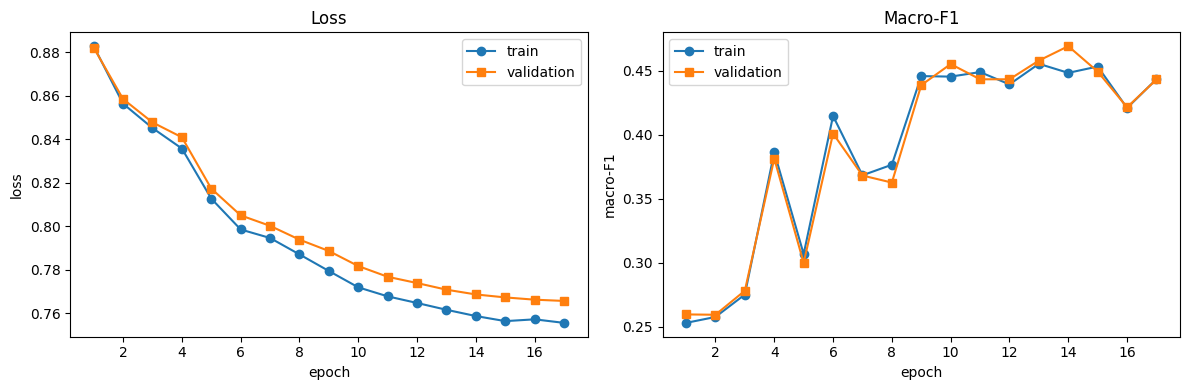


Evaluating on Test Set:


Training Loss,Validation Loss,Epoch,Accuracy,F1,F1 Macro
0.796806,0.762809,17,0.657025,0.586589,0.455289


{'eval_loss': 0.7628093957901001, 'eval_accuracy': 0.6570247933884298, 'eval_f1': 0.5865889700957204, 'eval_f1_macro': 0.4552892301990545}



Classification Report:
              precision    recall  f1-score   support

    negative       0.73      0.18      0.29        61
     neutral       0.67      0.98      0.79       287
    positive       0.54      0.19      0.28       136

    accuracy                           0.66       484
   macro avg       0.65      0.45      0.46       484
weighted avg       0.64      0.66      0.59       484


EXAMPLE PREDICTIONS (First 10 samples)

[1] True: positive | Pred: negative
    Text: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn .

[2] True: neutral  | Pred: neutral 
    Text: Elcoteq has a global network of After Market Service sites which have a long experience in serving C...

[3] True: neutral  | Pred: neutral 
    Text: Marubeni has participated in GHG - Green House Gas - emission reduction projects overseas , obtained...

[4] True: positive | Pred: neutral 
    Text: Finnish construction group Lemminkainen Oyj HEL : LEM1S said today it has won a contract

Model and tokenizer saved to ./models/bert_frozen_phrasebank


In [16]:
bert_results = train_bert_frozen()

# Distilled Bert (Encoder-Only 67M Parameters):

Model Card: https://huggingface.co/distilbert/distilbert-base-uncased

Configuration:
- attention_dropout: 0.1
- dim: 768
- dropout: 0.1
- hidden_dim: 3072
- initializer_range: 0.02
- max_position_embeddings: 512
- model_type: "distilbert"
- n_heads: 12
- n_layers: 6
- pad_token_id: 0
- qa_dropout: 0.1
- seq_classif_dropout: 0.2
- sinusoidal_pos_embds: false
- tie_weights_: true
- transformers_version: "4.10.0.dev0"
- vocab_size: 30522

In [17]:
# Constants
SAVE_PATH = "./models/distilbert_frozen_phrasebank"

def train_distilbert_frozen():
    set_seed(SEED)
    model_name = "distilbert/distilbert-base-uncased"
    print(f"Initializing {model_name} with frozen encoder...")

    # 1. Load Tokenizer
    tokenizer = DistilBertTokenizer.from_pretrained(model_name)

    # 2. Load Dataset
    if not all(os.path.exists(p) for p in [TRAIN_PATH, VAL_PATH, TEST_PATH]):
        print("Error: Data files not found. Running data preparation now.")
        prepare_data()

    raw_datasets = load_local_data()

    # Tokenization function
    def tokenize_function(examples):
        return tokenizer(examples["sentence"], truncation=True, padding=False)

    tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

    # 3. Load Model and Freeze Encoder
    # 3 labels: negative, neutral, positive
    model = DistilBertForSequenceClassification.from_pretrained(model_name, num_labels=3)

    # Freeze all DistilBERT parameters
    # In DistilBERT, the base model is accessible via model.distilbert
    for param in model.distilbert.parameters():
        param.requires_grad = False

    # Verify: The classification head (pre_classifier and classifier) should still have requires_grad = True
    print("\n--- DistilBert ---")
    for name, param in model.distilbert.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    print("\n--- Pre Classifier Head ---")
    for name, param in model.pre_classifier.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    print("\n--- Classifier Head ---")
    for name, param in model.classifier.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    # 4. Training Arguments
    training_args = TrainingArguments(
        output_dir="./results_distilbert_frozen",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-4,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=epochs,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_validation_f1_macro",
        greater_is_better=True,
        logging_steps=10,
        push_to_hub=False,
        report_to="none"
    )

    # Data Collator for dynamic padding
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    # 5. Trainer Initialization
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset={
        "validation": tokenized_datasets["validation"],
        "train": tokenized_datasets["train"],
        },
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )

    # 6. Start Training
    print("Starting training of the classification head...")
    trainer.train()

    import matplotlib.pyplot as plt

    logs = trainer.state.log_history
    def series(key):
        return [(l["epoch"], l[key]) for l in logs if key in l]

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4))

    axL.plot(*zip(*series("eval_train_loss")), "o-", label="train")
    axL.plot(*zip(*series("eval_validation_loss")), "s-", label="validation")
    axL.set_xlabel("epoch"); axL.set_ylabel("loss"); axL.set_title("Loss"); axL.legend()

    axR.plot(*zip(*series("eval_train_f1_macro")), "o-", label="train")
    axR.plot(*zip(*series("eval_validation_f1_macro")), "s-", label="validation")
    axR.set_xlabel("epoch"); axR.set_ylabel("macro-F1"); axR.set_title("Macro-F1"); axR.legend()

    plt.tight_layout(); plt.show()

    # 7. Final Evaluation on Test Set
    print("\nEvaluating on Test Set:")
    test_results = trainer.evaluate(tokenized_datasets["test"])
    print(test_results)

    show_clax_report_and_examples(trainer, tokenized_datasets, raw_datasets)

    # 8. Save the model
    os.makedirs(SAVE_PATH, exist_ok=True)
    model.save_pretrained(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)
    print(f"Model and tokenizer saved to {SAVE_PATH}")

    return {"base_distilbert" : test_results}

Initializing distilbert/distilbert-base-uncased with frozen encoder...



--- DistilBert ---
  FROZEN: embeddings.word_embeddings.weight
  FROZEN: embeddings.position_embeddings.weight
  FROZEN: embeddings.LayerNorm.weight
  FROZEN: embeddings.LayerNorm.bias
  FROZEN: transformer.layer.0.attention.q_lin.weight
  FROZEN: transformer.layer.0.attention.q_lin.bias
  FROZEN: transformer.layer.0.attention.k_lin.weight
  FROZEN: transformer.layer.0.attention.k_lin.bias
  FROZEN: transformer.layer.0.attention.v_lin.weight
  FROZEN: transformer.layer.0.attention.v_lin.bias
  FROZEN: transformer.layer.0.attention.out_lin.weight
  FROZEN: transformer.layer.0.attention.out_lin.bias
  FROZEN: transformer.layer.0.sa_layer_norm.weight
  FROZEN: transformer.layer.0.sa_layer_norm.bias
  FROZEN: transformer.layer.0.ffn.lin1.weight
  FROZEN: transformer.layer.0.ffn.lin1.bias
  FROZEN: transformer.layer.0.ffn.lin2.weight
  FROZEN: transformer.layer.0.ffn.lin2.bias
  FROZEN: transformer.layer.0.output_layer_norm.weight
  FROZEN: transformer.layer.0.output_layer_norm.bias
  FROZ

Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation F1,Validation F1 Macro,Train Loss,Train Accuracy,Train F1,Train F1 Macro
1,0.675592,No log,0.685950,0.686607,0.613977,0.661332,0.716684,0.714485,0.635551
2,0.719085,No log,0.704545,0.683699,0.612015,0.564775,0.756457,0.740829,0.683186
3,0.647737,No log,0.737603,0.734638,0.681160,0.526775,0.774019,0.771014,0.717292
4,0.564644,No log,0.743802,0.724593,0.646643,0.528351,0.771178,0.755755,0.685085
5,0.543474,No log,0.752066,0.746457,0.682676,0.493703,0.784349,0.779580,0.721449
6,0.554829,No log,0.716942,0.724572,0.676435,0.520865,0.763946,0.769432,0.730620
7,0.555827,No log,0.764463,0.761049,0.699665,0.487167,0.781508,0.776472,0.709716
8,0.581305,No log,0.752066,0.746212,0.689350,0.459734,0.804494,0.800997,0.756171
9,0.505017,No log,0.762397,0.754298,0.697762,0.453498,0.807851,0.803484,0.758426
10,0.485092,No log,0.772727,0.769190,0.709782,0.450639,0.802686,0.800566,0.753676


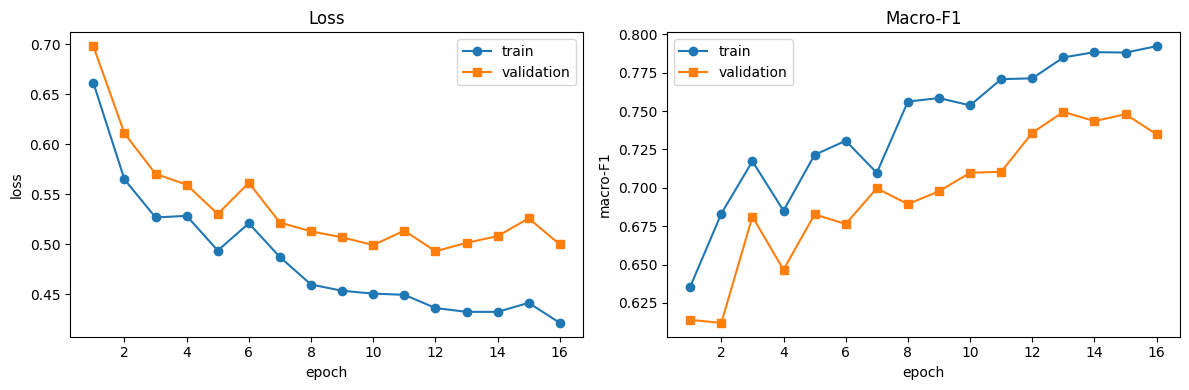


Evaluating on Test Set:


Training Loss,Validation Loss,Epoch,Accuracy,F1,F1 Macro
0.430114,0.499580,16,0.778926,0.779576,0.733081


{'eval_loss': 0.4995802640914917, 'eval_accuracy': 0.7789256198347108, 'eval_f1': 0.779575521835685, 'eval_f1_macro': 0.733080903698094}



Classification Report:
              precision    recall  f1-score   support

    negative       0.68      0.66      0.67        61
     neutral       0.86      0.84      0.85       287
    positive       0.67      0.70      0.68       136

    accuracy                           0.78       484
   macro avg       0.73      0.73      0.73       484
weighted avg       0.78      0.78      0.78       484


EXAMPLE PREDICTIONS (First 10 samples)

[1] True: positive | Pred: negative
    Text: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn .

[2] True: neutral  | Pred: neutral 
    Text: Elcoteq has a global network of After Market Service sites which have a long experience in serving C...

[3] True: neutral  | Pred: positive
    Text: Marubeni has participated in GHG - Green House Gas - emission reduction projects overseas , obtained...

[4] True: positive | Pred: positive
    Text: Finnish construction group Lemminkainen Oyj HEL : LEM1S said today it has won a contract

Model and tokenizer saved to ./models/distilbert_frozen_phrasebank


In [18]:
distilbert_results = train_distilbert_frozen()

# FinBert (Encoder-Only 110M Parameters):

Model Card: https://huggingface.co/yiyanghkust/finbert-pretrain

Configuration:
- attention_probs_dropout_prob: 0.1
- hidden_act: "gelu"
- hidden_dropout_prob: 0.1
- hidden_size: 768
- initializer_range: 0.02
- intermediate_size: 3072
- max_position_embeddings: 512
- num_attention_heads: 12
- num_hidden_layers: 12
- type_vocab_size: 2
- vocab_size: 30873

In [19]:
SAVE_PATH = "./models/finbert_frozen_phrasebank"

def train_finbert_frozen():
    set_seed(SEED)
    # Use the version pre-trained on financial documents (but not sentiment labels)
    model_name = "yiyanghkust/finbert-pretrain"
    print(f"Initializing {model_name} with frozen financial encoder...")

    # Load Tokenizer
    tokenizer = BertTokenizer.from_pretrained(model_name)

    # Load Dataset
    raw_datasets = load_local_data()

    # Tokenization function
    def tokenize_function(examples):
        return tokenizer(examples["sentence"], truncation=True, padding=False)

    tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

    # 3. Load Model and Freeze Encoder
    model = BertForSequenceClassification.from_pretrained(model_name, num_labels=3)

    # Freeze the financial encoder
    for param in model.bert.parameters():
        param.requires_grad = False

    print("\n--- BERT ---")
    for name, param in model.bert.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    print("\n--- Classifier Head ---")
    for name, param in model.classifier.named_parameters():
        status = "TRAINABLE" if param.requires_grad else "FROZEN"
        print(f"  {status}: {name}")

    # 4. Training Arguments
    # Note: Using eval_strategy for transformers v5 compatibility
    training_args = TrainingArguments(
        output_dir="./results_finbert_frozen",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-4,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=epochs,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_validation_f1_macro",
        greater_is_better=True,
        logging_steps=10,
        push_to_hub=False,
        report_to="none"
    )

    # Data Collator
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    # 5. Trainer Initialization (using processing_class for transformers v5)
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset={
        "validation": tokenized_datasets["validation"],
        "train": tokenized_datasets["train"],
        },
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )

    # 6. Start Training
    print("Starting training of the classification head on Financial BERT...")
    trainer.train()

    import matplotlib.pyplot as plt

    logs = trainer.state.log_history
    def series(key):
        return [(l["epoch"], l[key]) for l in logs if key in l]

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4))

    axL.plot(*zip(*series("eval_train_loss")), "o-", label="train")
    axL.plot(*zip(*series("eval_validation_loss")), "s-", label="validation")
    axL.set_xlabel("epoch"); axL.set_ylabel("loss"); axL.set_title("Loss"); axL.legend()

    axR.plot(*zip(*series("eval_train_f1_macro")), "o-", label="train")
    axR.plot(*zip(*series("eval_validation_f1_macro")), "s-", label="validation")
    axR.set_xlabel("epoch"); axR.set_ylabel("macro-F1"); axR.set_title("Macro-F1"); axR.legend()

    plt.tight_layout(); plt.show()

    # 7. Final Evaluation on Test Set
    print("\nEvaluating on Test Set:")
    test_results = trainer.evaluate(tokenized_datasets["test"])
    print(test_results)

    show_clax_report_and_examples(trainer, tokenized_datasets, raw_datasets)

    # Save the model
    os.makedirs("models", exist_ok=True)
    model.save_pretrained(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)
    print(f"Model and tokenizer saved to {SAVE_PATH}")

    return {"finbert" : test_results}

Initializing yiyanghkust/finbert-pretrain with frozen financial encoder...



--- BERT ---
  FROZEN: embeddings.word_embeddings.weight
  FROZEN: embeddings.position_embeddings.weight
  FROZEN: embeddings.token_type_embeddings.weight
  FROZEN: embeddings.LayerNorm.weight
  FROZEN: embeddings.LayerNorm.bias
  FROZEN: encoder.layer.0.attention.self.query.weight
  FROZEN: encoder.layer.0.attention.self.query.bias
  FROZEN: encoder.layer.0.attention.self.key.weight
  FROZEN: encoder.layer.0.attention.self.key.bias
  FROZEN: encoder.layer.0.attention.self.value.weight
  FROZEN: encoder.layer.0.attention.self.value.bias
  FROZEN: encoder.layer.0.attention.output.dense.weight
  FROZEN: encoder.layer.0.attention.output.dense.bias
  FROZEN: encoder.layer.0.attention.output.LayerNorm.weight
  FROZEN: encoder.layer.0.attention.output.LayerNorm.bias
  FROZEN: encoder.layer.0.intermediate.dense.weight
  FROZEN: encoder.layer.0.intermediate.dense.bias
  FROZEN: encoder.layer.0.output.dense.weight
  FROZEN: encoder.layer.0.output.dense.bias
  FROZEN: encoder.layer.0.output.Lay

Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation F1,Validation F1 Macro,Train Loss,Train Accuracy,Train F1,Train F1 Macro
1,0.797617,No log,0.669421,0.603884,0.413469,0.757021,0.672004,0.603814,0.414329
2,0.762417,No log,0.688017,0.634873,0.495014,0.699153,0.682335,0.623906,0.476508
3,0.703639,No log,0.696281,0.650705,0.509662,0.659059,0.706612,0.662176,0.520042
4,0.672085,No log,0.706612,0.673506,0.533907,0.634431,0.718233,0.682973,0.541599
5,0.645231,No log,0.721074,0.694776,0.604344,0.614439,0.735021,0.708717,0.615567
6,0.722235,No log,0.739669,0.721891,0.662112,0.596468,0.753874,0.737053,0.673179
7,0.697811,No log,0.729339,0.713714,0.629340,0.584780,0.754132,0.739199,0.664930
8,0.679102,No log,0.743802,0.725127,0.668434,0.577736,0.759039,0.742313,0.684524
9,0.531014,No log,0.741736,0.733290,0.671394,0.567504,0.766012,0.755408,0.690399
10,0.613996,No log,0.743802,0.733167,0.685272,0.560903,0.767045,0.755183,0.697078


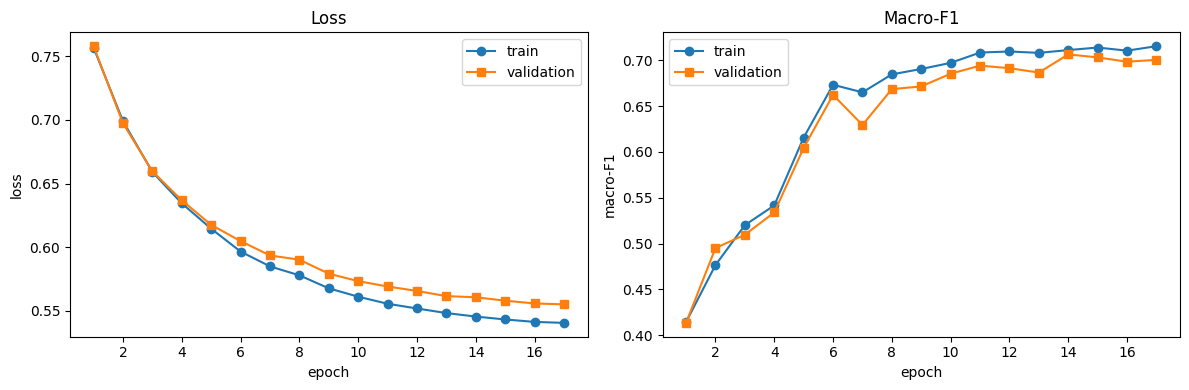


Evaluating on Test Set:


Training Loss,Validation Loss,Epoch,Accuracy,F1,F1 Macro
0.591914,0.576547,17,0.754132,0.741760,0.671155


{'eval_loss': 0.5765467882156372, 'eval_accuracy': 0.7541322314049587, 'eval_f1': 0.7417603518044572, 'eval_f1_macro': 0.6711548317422923}



Classification Report:
              precision    recall  f1-score   support

    negative       0.69      0.48      0.56        61
     neutral       0.78      0.91      0.84       287
    positive       0.69      0.54      0.61       136

    accuracy                           0.75       484
   macro avg       0.72      0.64      0.67       484
weighted avg       0.74      0.75      0.74       484


EXAMPLE PREDICTIONS (First 10 samples)

[1] True: positive | Pred: negative
    Text: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn .

[2] True: neutral  | Pred: neutral 
    Text: Elcoteq has a global network of After Market Service sites which have a long experience in serving C...

[3] True: neutral  | Pred: positive
    Text: Marubeni has participated in GHG - Green House Gas - emission reduction projects overseas , obtained...

[4] True: positive | Pred: neutral 
    Text: Finnish construction group Lemminkainen Oyj HEL : LEM1S said today it has won a contract

Model and tokenizer saved to ./models/finbert_frozen_phrasebank


In [20]:
finbert_results = train_finbert_frozen()

# FinBert (Full Pretrained Classifier 110M Parameters):

Model Card: https://huggingface.co/ProsusAI/finbert

Configuration:
- attention_probs_dropout_prob: 0.1
- gradient_checkpointing: false
- hidden_act: "gelu"
- hidden_dropout_prob: 0.1
- hidden_size: 768
- id2label:
  - 0: "positive"
  - 1: "negative"
  - 2: "neutral"
- initializer_range: 0.02
- intermediate_size: 3072
- label2id:
  - "positive": 0
  - "negative": 1
  - "neutral": 2
- layer_norm_eps: 1e-12
- max_position_embeddings: 512
- model_type: "bert"
- num_attention_heads: 12
- num_hidden_layers: 12
- pad_token_id: 0
- position_embedding_type: "absolute"
- type_vocab_size: 2
- vocab_size: 30522

> **Note on this model.** `ProsusAI/finbert` was fine-tuned on the Financial PhraseBank, the same corpus used for this benchmark. Its training sentences very likely overlap with this test split, so its score is an **upper reference, not a held-out result**. The best model trained in this notebook is the DistilBERT classifier head.

In [24]:
SAVE_PATH = "./models/finbert_prosus_ai"

def evaluate_final_finbert():
    # This is the fully fine-tuned SOTA model
    model_name = "ProsusAI/finbert"
    print(f"Loading fully trained SOTA model: {model_name}...")

    # Load Tokenizer and Model
    tokenizer = BertTokenizer.from_pretrained(model_name)
    model = BertForSequenceClassification.from_pretrained(model_name)

    # Load local datasets
    raw_datasets = load_local_data()
    raw_test_dataset = raw_datasets["test"]

    # IMPORTANT: Remap labels to match ProsusAI/finbert mapping:
    # Original (lmassaron): 0: neg, 1: neu, 2: pos
    # Target (FinBERT): 0: pos, 1: neg, 2: neu
    def align_labels(example):
        orig_label = example["label"]
        if orig_label == 0: # neg
            new_label = 1
        elif orig_label == 1: # neu
            new_label = 2
        else: # pos (2)
            new_label = 0
        example["label"] = new_label
        return example

    test_dataset = raw_test_dataset.map(align_labels)

    # Tokenization function
    def tokenize_function(examples):
        return tokenizer(examples["sentence"], truncation=True, padding=False)

    tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
    tokenized_test = test_dataset.map(tokenize_function, batched=True)

    # 3. Setup Trainer for evaluation only
    training_args = TrainingArguments(
        output_dir="./results_finbert_final",
        per_device_eval_batch_size=16,
        report_to="none"
    )

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    trainer = Trainer(
        model=model,
        args=training_args,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    # 4. Final Evaluation
    print("\nRunning evaluation on test set (No training needed)...")
    test_results = trainer.evaluate(tokenized_test)

    # --- corrected report for the full FinBERT model ---
    # Use the REMAPPED test set (tokenized_test) so labels are in ProsusAI's language,
    # and use ProsusAI's label order for the names: 0=positive, 1=negative, 2=neutral
    test_predictions = trainer.predict(tokenized_test)
    test_preds = np.argmax(test_predictions.predictions, axis=-1)
    y_true = test_predictions.label_ids

    prosus_target_names = ['positive', 'negative', 'neutral']

    print("\nClassification Report:")
    print(classification_report(y_true, test_preds, target_names=prosus_target_names))

    test_sentences = raw_datasets["test"]["sentence"]
    print("\n" + "="*60)
    print("EXAMPLE PREDICTIONS (First 10 samples)")
    print("="*60)
    for i in range(min(10, len(test_sentences))):
        sentence = test_sentences[i]
        display_sentence = sentence[:100] + "..." if len(sentence) > 100 else sentence
        print(f"\n[{i+1}] True: {prosus_target_names[y_true[i]]:8} | Pred: {prosus_target_names[test_preds[i]]:8}")
        print(f"    Text: {display_sentence}")

    print("\n--- FINAL SOTA FINBERT RESULTS ---")
    print(f"Test Accuracy: {test_results['eval_accuracy']:.4f}")
    print(f"Test Loss: {test_results['eval_loss']:.4f}")
    print("-----------------------------------")

    # Save the model
    os.makedirs("models", exist_ok=True)
    model.save_pretrained(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)
    print(f"Model and tokenizer saved to {SAVE_PATH}")

    return {"finbert (full)" : test_results}

In [25]:
full_finbert_results = evaluate_final_finbert()

Loading fully trained SOTA model: ProsusAI/finbert...



Running evaluation on test set (No training needed)...


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
No log,0.332213,0,0.884298,0.885723,0.874053



Classification Report:
              precision    recall  f1-score   support

    positive       0.82      0.92      0.87       136
    negative       0.77      0.97      0.86        61
     neutral       0.96      0.85      0.90       287

    accuracy                           0.88       484
   macro avg       0.85      0.91      0.87       484
weighted avg       0.90      0.88      0.89       484


EXAMPLE PREDICTIONS (First 10 samples)

[1] True: positive | Pred: positive
    Text: Loss after taxes amounted to EUR 1.2 mn compared to a loss of 2.6 mn .

[2] True: neutral  | Pred: neutral 
    Text: Elcoteq has a global network of After Market Service sites which have a long experience in serving C...

[3] True: neutral  | Pred: neutral 
    Text: Marubeni has participated in GHG - Green House Gas - emission reduction projects overseas , obtained...

[4] True: positive | Pred: positive
    Text: Finnish construction group Lemminkainen Oyj HEL : LEM1S said today it has won a contract

Model and tokenizer saved to ./models/finbert_prosus_ai


# Full Model Benchmarking:

In [26]:
all_results = {
    **majority_results,
    **lm_results,
    **lr_results,
    **bert_results,
    **distilbert_results,
    **finbert_results,
    **full_finbert_results
}

df = pd.DataFrame(all_results).T  # Transpose so models are rows

df = df[["eval_accuracy", "eval_f1", "eval_f1_macro", "eval_loss"]]

print(df)

                     eval_accuracy   eval_f1  eval_f1_macro  eval_loss
majority_class            0.592975  0.441463       0.248163        NaN
LM                        0.549587  0.543907       0.431627        NaN
logistic_regression       0.706612  0.680246       0.591720        NaN
base_bert                 0.657025  0.586589       0.455289   0.762809
base_distilbert           0.778926  0.779576       0.733081   0.499580
finbert                   0.754132  0.741760       0.671155   0.576547
finbert (full)            0.884298  0.885723       0.874053   0.332213


In [27]:
test_df = pd.read_csv(TEST_PATH)
comparison_samples = test_df.head(10).copy()

# 2. Setup Label Mappings
idx_to_label = {0: "negative", 1: "neutral", 2: "positive"}
finbert_full_idx_to_label = {0: "positive", 1: "negative", 2: "neutral"}

# 3. Load all models
print("Loading all models for comparison...")

lm = ps.LM()
lr_model = joblib.load("models/logistic_regression/logistic_regression_tfidf.joblib")
lr_vectorizer = joblib.load("models/logistic_regression/tfidf_vectorizer.joblib")

bert_tokenizer = BertTokenizer.from_pretrained("./models/bert_frozen_phrasebank")
bert_model = BertForSequenceClassification.from_pretrained("./models/bert_frozen_phrasebank")

distilbert_tokenizer = DistilBertTokenizer.from_pretrained("./models/distilbert_frozen_phrasebank")
distilbert_model = DistilBertForSequenceClassification.from_pretrained("./models/distilbert_frozen_phrasebank")

finbert_frozen_tokenizer = BertTokenizer.from_pretrained("./models/finbert_frozen_phrasebank")
finbert_frozen_model = BertForSequenceClassification.from_pretrained("./models/finbert_frozen_phrasebank")

finbert_full_tokenizer = BertTokenizer.from_pretrained("./models/finbert_prosus_ai")
finbert_full_model = BertForSequenceClassification.from_pretrained("./models/finbert_prosus_ai")

# 4. Prediction functions
def predict_lm(text):
    tokens = lm.tokenize(text)
    score = lm.get_score(tokens)
    polarity = score['Polarity']
    if polarity > 0: return "positive"
    elif polarity < 0: return "negative"
    else: return "neutral"

def predict_lr(text):
    X = lr_vectorizer.transform([text])
    pred = lr_model.predict(X)[0]
    return idx_to_label[pred]

def predict_transformer(text, model, tokenizer, mapping):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits
    pred = torch.argmax(logits, dim=-1).item()
    return mapping[pred]

# 5. Collect Predictions
results = []
for _, row in comparison_samples.iterrows():
    sentence = row['sentence']

    results.append({
        "sentence": sentence,
        "LM model": predict_lm(sentence),
        "LR model": predict_lr(sentence),
        "Bert model": predict_transformer(sentence, bert_model, bert_tokenizer, idx_to_label),
        "DistilBert model": predict_transformer(sentence, distilbert_model, distilbert_tokenizer, idx_to_label),
        "FinBert model": predict_transformer(sentence, finbert_frozen_model, finbert_frozen_tokenizer, idx_to_label),
        "Finbert (full) model": predict_transformer(sentence, finbert_full_model, finbert_full_tokenizer, finbert_full_idx_to_label),
        "true label": row['label_name']
    })

# 6. Create Comparison DataFrame
comparison_df = pd.DataFrame(results)
comparison_df

Loading all models for comparison...


,sentence,LM model,LR model,Bert model,DistilBert model,FinBert model,Finbert (full) model,true label
0,Loss after taxes amounted to EUR 1.2 mn compar...,negative,negative,negative,negative,negative,positive,positive
1,Elcoteq has a global network of After Market S...,neutral,positive,neutral,neutral,neutral,neutral,neutral
2,Marubeni has participated in GHG - Green House...,neutral,neutral,neutral,positive,positive,neutral,neutral
3,Finnish construction group Lemminkainen Oyj HE...,neutral,positive,neutral,positive,neutral,positive,positive
4,"Outokumpu 's steel mill in Tornio , in Finland...",negative,neutral,neutral,neutral,neutral,negative,negative
5,"Z. Bavelloni 's long-standing MD , Dino Bavell...",neutral,neutral,neutral,neutral,neutral,neutral,neutral
6,"The podcast , sees Harple provide the low-down...",positive,neutral,neutral,neutral,neutral,neutral,neutral
7,In the financial statement for the first quart...,negative,neutral,neutral,negative,neutral,negative,neutral
8,23 April 2010 - Finnish construction and engin...,positive,positive,positive,negative,positive,negative,negative
9,30 November 2009 - Finnish office furniture ma...,neutral,negative,neutral,negative,negative,negative,negative


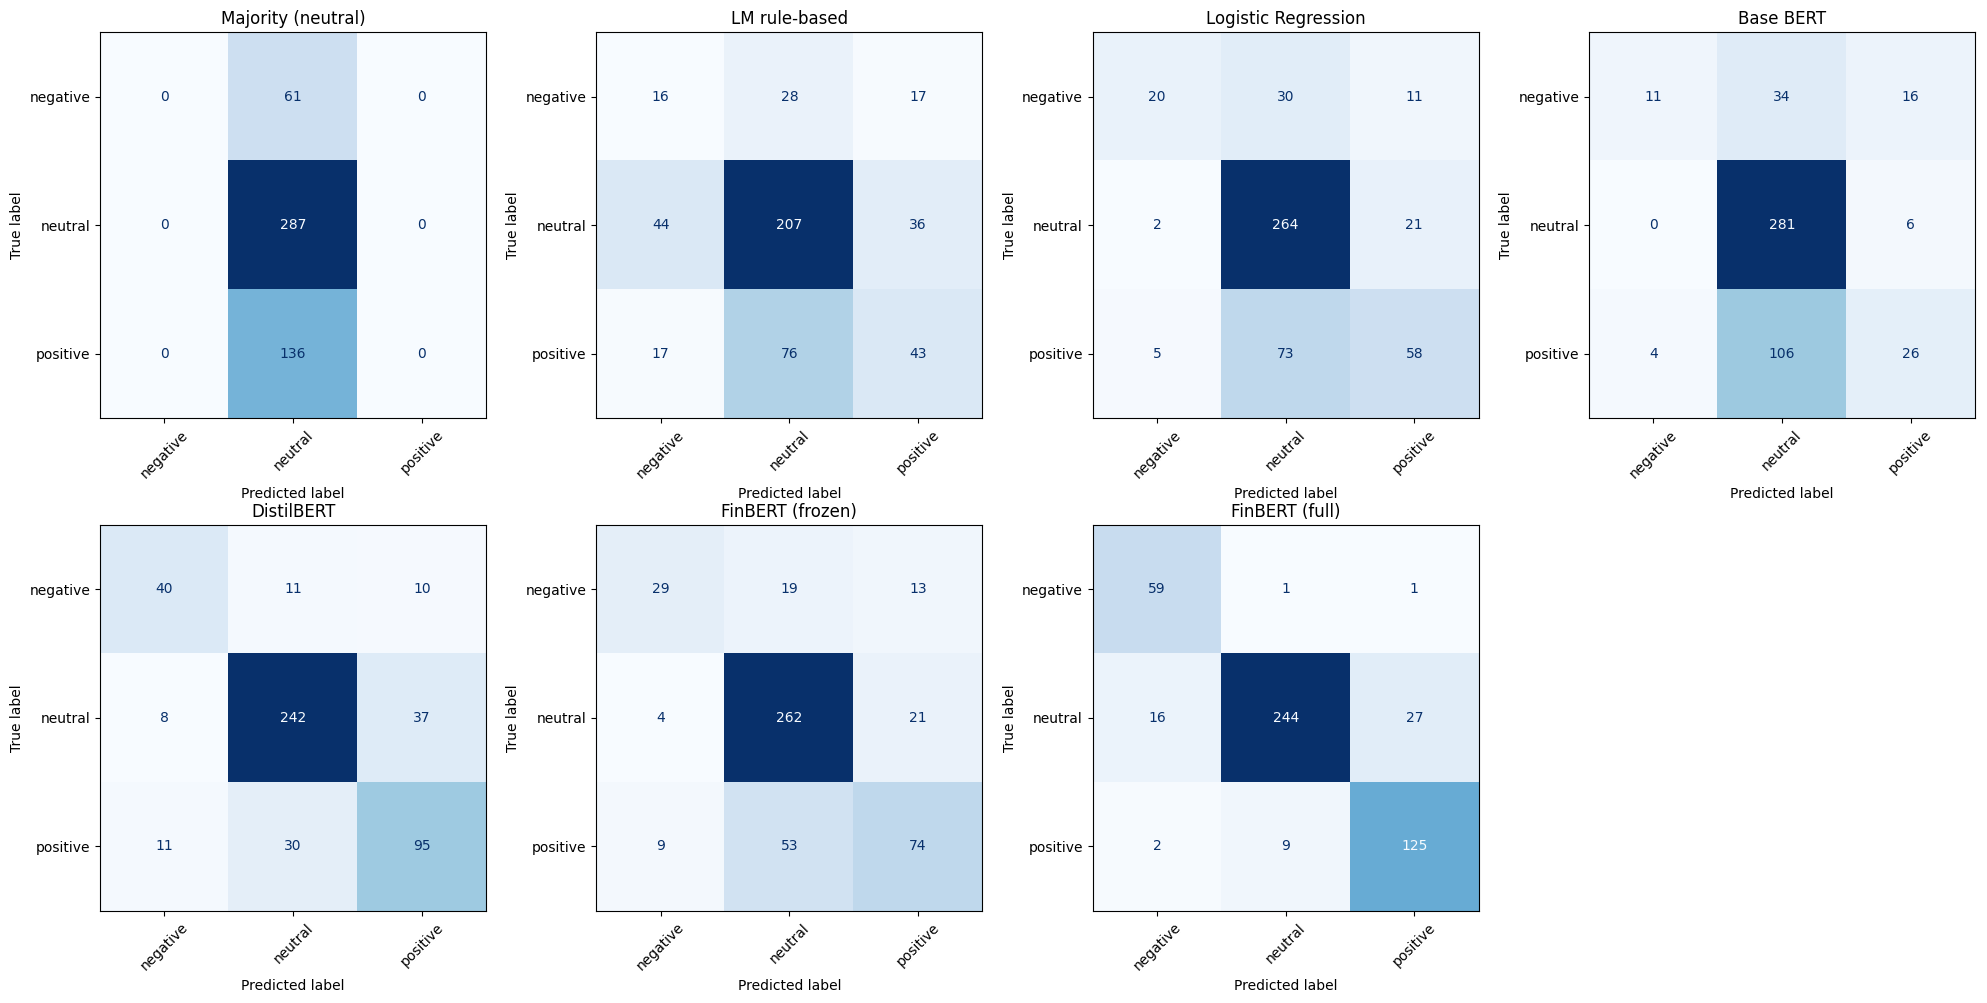

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm

import matplotlib.pyplot as plt

labels_order = ["negative", "neutral", "positive"]

test_df_full = pd.read_csv(TEST_PATH)
sentences = test_df_full["sentence"].tolist()
y_true = test_df_full["label_name"].tolist()

# Each entry maps a model name -> a function that turns a sentence into a label string
model_predictors = {
    "Majority (neutral)":  lambda s: "neutral",
    "LM rule-based":       predict_lm,
    "Logistic Regression": predict_lr,
    "Base BERT":           lambda s: predict_transformer(s, bert_model, bert_tokenizer, idx_to_label),
    "DistilBERT":          lambda s: predict_transformer(s, distilbert_model, distilbert_tokenizer, idx_to_label),
    "FinBERT (frozen)":    lambda s: predict_transformer(s, finbert_frozen_model, finbert_frozen_tokenizer, idx_to_label),
    "FinBERT (full)":      lambda s: predict_transformer(s, finbert_full_model, finbert_full_tokenizer, finbert_full_idx_to_label),
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for ax, (name, predict_fn) in zip(axes, model_predictors.items()):
    y_pred = [predict_fn(s) for s in tqdm(sentences, desc=name, leave=True)]
    cm = confusion_matrix(y_true, y_pred, labels=labels_order)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.set_xticklabels(labels_order, rotation=45)

# hide the leftover empty subplot (7 models in an 8-slot grid)
for ax in axes[len(model_predictors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Reuse predictions if already computed; otherwise compute them once (with a bar).
try:
    model_preds
except NameError:
    model_preds = {name: [fn(s) for s in tqdm(sentences, desc=name, leave=True)]
                   for name, fn in model_predictors.items()}

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    n = len(y_true)
    boot = [metric_fn(y_true[i], y_pred[i])
            for i in (rng.integers(0, n, n) for _ in range(n_boot))]
    point = metric_fn(y_true, y_pred)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return point, lo, hi

macro_f1 = lambda t, p: f1_score(t, p, average="macro", labels=labels_order, zero_division=0)

# Compute everything first (with a progress bar), then print the table.
rows = []
for name, y_pred in tqdm(model_preds.items(), desc="Bootstrapping", total=len(model_preds)):
    a, alo, ahi = bootstrap_ci(y_true, y_pred, accuracy_score)
    f, flo, fhi = bootstrap_ci(y_true, y_pred, macro_f1)
    rows.append((name, a, alo, ahi, f, flo, fhi))

print(f"\n95% bootstrap confidence intervals (test set = {len(y_true)} rows)\n")
print(f"{'Model':<22}{'Accuracy (95% CI)':<30}{'Macro-F1 (95% CI)'}")
for name, a, alo, ahi, f, flo, fhi in rows:
    print(f"{name:<22}{a:.3f} [{alo:.3f}, {ahi:.3f}]        {f:.3f} [{flo:.3f}, {fhi:.3f}]")


95% bootstrap confidence intervals (test set = 484 rows)

Model                 Accuracy (95% CI)             Macro-F1 (95% CI)
Majority (neutral)    0.593 [0.548, 0.636]        0.248 [0.236, 0.259]
LM rule-based         0.550 [0.506, 0.593]        0.432 [0.386, 0.477]
Logistic Regression   0.707 [0.665, 0.746]        0.592 [0.532, 0.648]
Base BERT             0.657 [0.614, 0.698]        0.455 [0.397, 0.511]
DistilBERT            0.779 [0.744, 0.814]        0.733 [0.688, 0.778]
FinBERT (frozen)      0.754 [0.717, 0.791]        0.671 [0.617, 0.723]
FinBERT (full)        0.884 [0.857, 0.911]        0.874 [0.841, 0.905]
